# Spike: do reflection ghosts leave plane peaks in the point clouds?

**Question.** Can we find the reflecting planes (floor, walls) from pairs of points inside one frame? If we can, we can build the ghost filter and estimate the room size.

**Method.** A real point P and its ghost G mirror each other across a plane. The plane is the perpendicular bisector of P-G. For every pair in a frame, we compute this plane: its normal direction and its distance `d` from the sensor. We keep a pair only if G is farther from the sensor **and** has a lower SNR than P, and if the points are at least 0.3 m apart.

**Control.** We repeat the same count for pairs of points from two frames that are far apart in time. A ghost exists only inside one frame. So a real plane must get more votes inside a frame than in the control. Random geometry gives equal votes.

**Pass rule.** The floor needs a peak above 5 sigma that sits near the floor distance (median y, about 1.8 m). The walls need cells above 5 sigma.

**Data.** 3 recordings of `room1` (Config_4, not excluded), 3 different sessions. The code is in `scripts/archive/ghost_plane_spike.py`. It ran on `haukurs_pc`.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

OUT = Path("../../results/ghost_spike")
summary = pd.DataFrame(json.load(open(OUT / "summary.json"))).T
summary.index.name = "recording"
cols = ["points", "pairs_within", "median_y_all_m", "median_y_lying_m", "floor_peak_d_m", "floor_peak_sigma",
        "wall_peak_sigma", "n_cells_wall_over_5_sigma"]
summary[cols].round(2)

,points,pairs_within,median_y_all_m,median_y_lying_m,floor_peak_d_m,floor_peak_sigma,wall_peak_sigma,n_cells_wall_over_5_sigma
recording,,,,,,,,
2311__20231115_135843,2993.0,3818.0,1.77,1.82,2.87,2.04,2.47,0.0
2311__20231120_144541,6033.0,7088.0,1.83,1.85,3.02,2.98,3.44,0.0
2311__20231120_153152,4597.0,6070.0,1.83,1.70,1.22,3.99,3.02,0.0


## Figures
Left: share of pairs by plane distance, for plane normals near the boresight (floor candidates). A floor would show a blue peak that the orange control does not have, near the dashed line. Middle: the difference in sigma. Right: wall candidates, as a map of normal direction against distance. A wall would be a red spot.

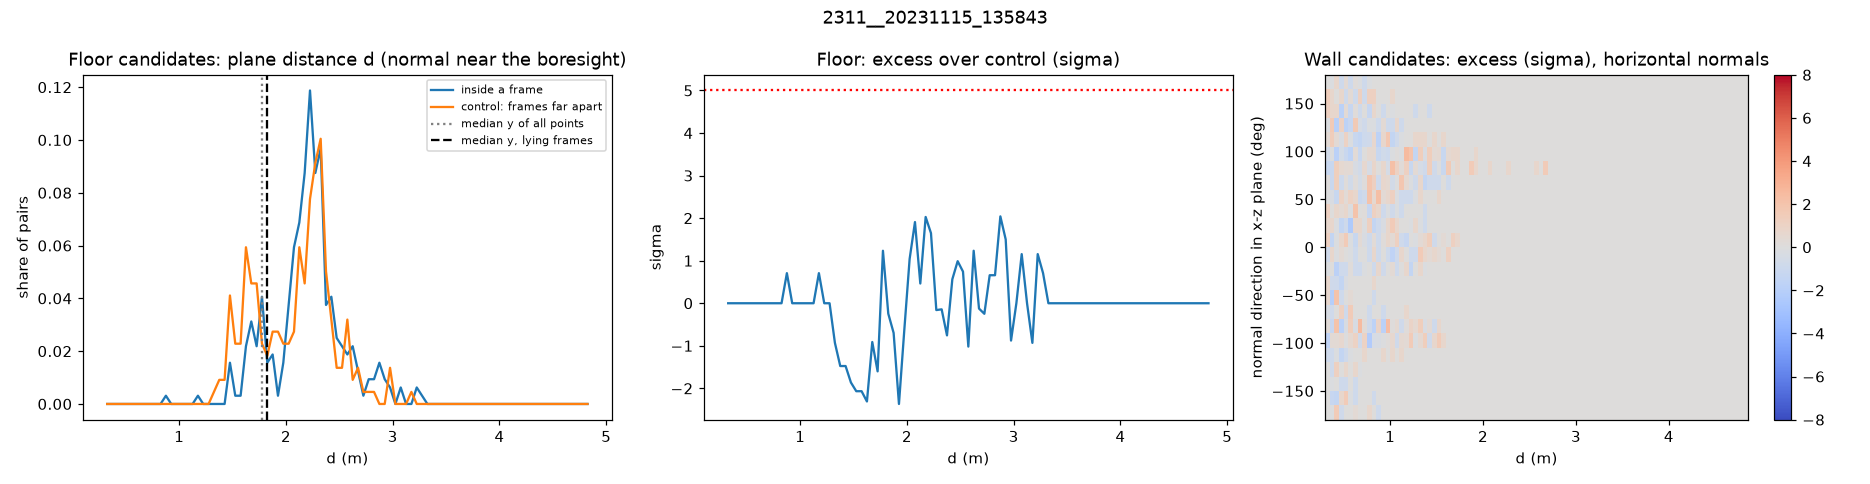

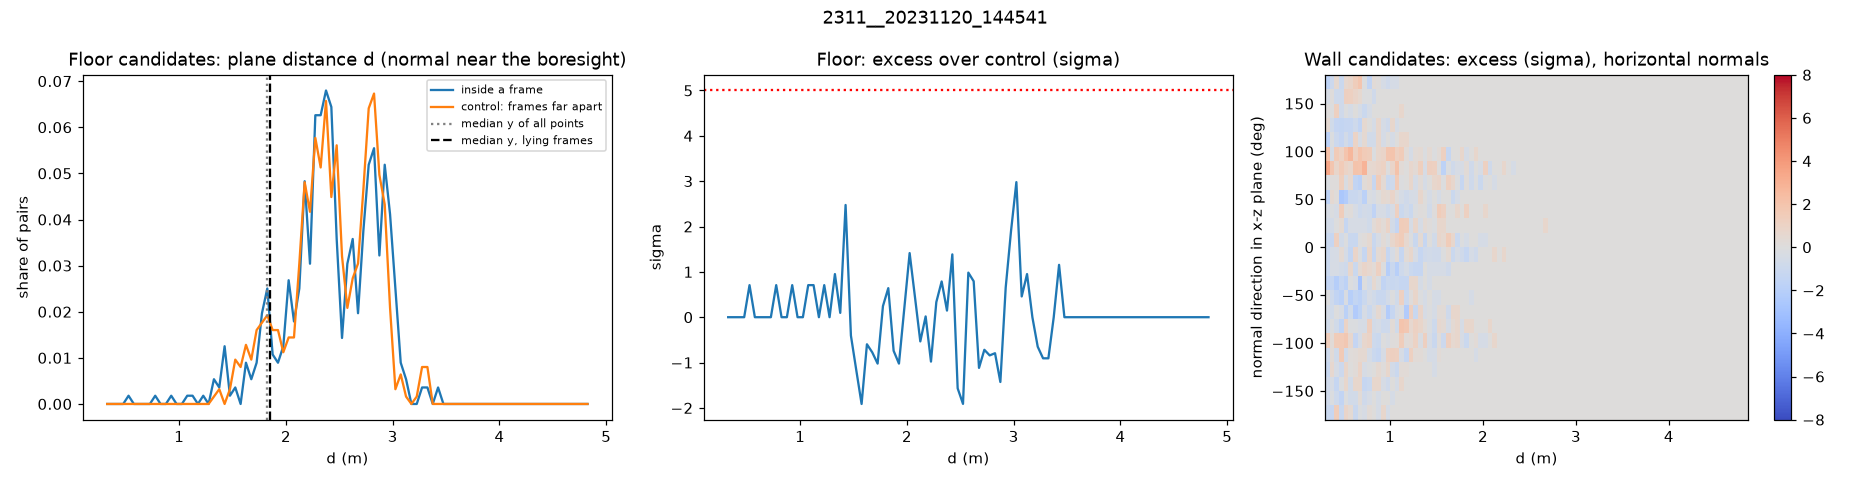

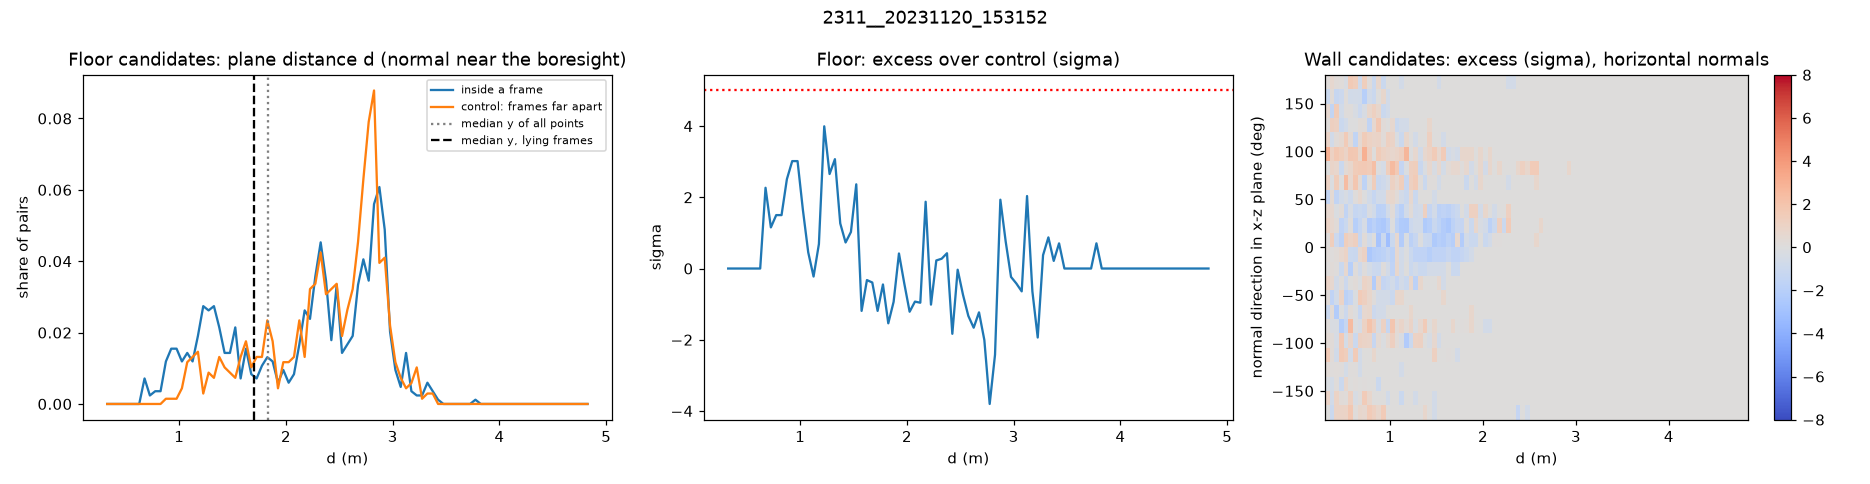

In [2]:
for name in summary.index:
    display(Image(str(OUT / f"{name}.png")))

## Result: no-go for this method as it stands

- **Floor.** The blue (inside a frame) and orange (control) curves are almost the same. The best peak is 2 to 4 sigma, below the 5 sigma rule. It is at 1.2 m, 2.9 m or 3.0 m. It is never near the floor distance of about 1.8 m. In every recording the best peak is at a different place, which is what noise looks like.
- **Walls.** No cell is above 5 sigma in any of the 3 recordings.
- **Few pairs.** Only about 2 pairs per frame pass the rules (3 800 to 7 100 pairs for 1 600 to 1 900 frames). The votes are too few for a clear peak.

## Why this is not yet a final answer

1. **The test cannot see the strongest floor ghost.** The sensor looks down. A floor bounce of a point at height y puts the ghost at about 2h - y. For a person who lies on the floor, y is near h, so the ghost is almost on top of the real point. The pair is closer than 0.3 m, so I removed it. The floor ghost may exist and still be invisible here.
2. **The sideways resolution is coarse.** The bisector normal of two close points is very noisy.
3. **No Doppler check.** A ghost and its real point should have related Doppler. We did not use it.
4. **Clutter removal is on.** Only moving things make ghosts, and only 3 recordings were used.

## What I recommend

Do **not** build the preprocessor yet. Run one more cheap spike that tests only the floor ghost along the range direction: for each point, look for a second point in the same frame at y close to 2h - y (h from the recording's floor estimate), with a lower SNR and a related Doppler. Compare with the control as before. If this also finds nothing, the point clouds hold no usable multipath, and we stop the filter and the room-size idea.